# Using Spark, Stopwords, RegularExpression, Matplotlib for Word Cloud

In [1]:
#pip install wordcloud
import matplotlib.pyplot as plt
import re
from wordcloud import WordCloud, STOPWORDS
from pyspark import SparkConf, SparkContext
from pyspark.sql import SparkSession

spark = SparkSession.builder.master('local').getOrCreate()

# Create Spark Context and load text file

In [2]:
sc = spark.sparkContext
text_file = sc.textFile('data/manncomm.txt')
#text_file = sc.textFile('data/santi.txt')
text_file.take(20)
#type(text_file)

['MANIFESTO OF THE COMMUNIST PARTY',
 '',
 '[From the English edition of 1888, edited by Friedrich Engels]',
 '',
 '',
 'A spectre is haunting Europe--the spectre of Communism.',
 'All the Powers of old Europe have entered into a holy alliance to',
 'exorcise this spectre: Pope and Czar, Metternich and Guizot,',
 'French Radicals and German police-spies.',
 '',
 'Where is the party in opposition that has not been decried as',
 'Communistic by its opponents in power?  Where is the Opposition',
 'that has not hurled back the branding reproach of Communism,',
 'against the more advanced opposition parties, as well as against',
 'its reactionary adversaries?',
 '',
 'Two things result from this fact.',
 '',
 'I.  Communism is already acknowledged by all European Powers',
 'to be itself a Power.']

In [3]:
#remove some punctuations
def removeSomePunctuation(text):
    #return re.sub(r'[^a-z0-9\s]','', text.lower().strip())
    return re.sub(r"[^a-z-'\s]",'', text.lower()) # only keep characters: a-z, - ,and ' in a line

rdd = text_file.map(lambda x: (removeSomePunctuation(x)))
rdd.take(10)

['manifesto of the communist party',
 '',
 'from the english edition of  edited by friedrich engels',
 '',
 '',
 'a spectre is haunting europe--the spectre of communism',
 'all the powers of old europe have entered into a holy alliance to',
 'exorcise this spectre pope and czar metternich and guizot',
 'french radicals and german police-spies',
 '']

In [4]:
#remove empty lines
rdd = rdd.filter(lambda x: x != '')
rdd.take(20)

['manifesto of the communist party',
 'from the english edition of  edited by friedrich engels',
 'a spectre is haunting europe--the spectre of communism',
 'all the powers of old europe have entered into a holy alliance to',
 'exorcise this spectre pope and czar metternich and guizot',
 'french radicals and german police-spies',
 'where is the party in opposition that has not been decried as',
 'communistic by its opponents in power  where is the opposition',
 'that has not hurled back the branding reproach of communism',
 'against the more advanced opposition parties as well as against',
 'its reactionary adversaries',
 'two things result from this fact',
 'i  communism is already acknowledged by all european powers',
 'to be itself a power',
 'ii  it is high time that communists should openly in the',
 'face of the whole world publish their views their aims their',
 'tendencies and meet this nursery tale of the spectre of',
 'communism with a manifesto of the party itself',
 'to thi

# Word Count, sort by key

In [5]:
#word count a text file read by pyspark
counts = rdd.flatMap(lambda x: ((v) for v in re.split('\\W',x))).filter(lambda x: x != '') \
        .map(lambda word: (word, 1)).reduceByKey(lambda a, b: a + b)
#counts = rdd.flatMap(lambda x: ((v) for v in re.split('\\W',x))) \
#                   .map(lambda word: (word, 1)).reduceByKey(lambda a, b: a + b)

output = counts.sortByKey().collectAsMap()
print(output)
type(output)

{'a': 164, 'ablaze': 1, 'able': 2, 'abolish': 3, 'abolished': 2, 'abolishes': 2, 'abolishing': 2, 'abolition': 20, 'about': 5, 'above': 5, 'absence': 2, 'absolute': 5, 'absolutely': 1, 'absolutism': 2, 'absurdity': 1, 'accompanied': 3, 'accomplished': 1, 'accordance': 1, 'according': 3, 'account': 1, 'accumulated': 2, 'accusation': 2, 'achieve': 1, 'acknowledged': 1, 'acquire': 3, 'acquired': 3, 'acquiring': 1, 'act': 1, 'action': 12, 'active': 1, 'activity': 2, 'acts': 2, 'actual': 1, 'acuteness': 1, 'adapted': 2, 'adequate': 1, 'administrative': 2, 'admire': 1, 'admit': 2, 'adopt': 1, 'adrift': 1, 'advance': 3, 'advanced': 4, 'advantage': 3, 'advantages': 1, 'adversaries': 1, 'affairs': 1, 'affect': 1, 'after': 5, 'afterwards': 1, 'again': 5, 'against': 34, 'age': 3, 'ages': 9, 'agglomerated': 1, 'agitation': 2, 'ago': 1, 'agrarian': 2, 'agreement': 1, 'agriculture': 6, 'aim': 2, 'aimed': 1, 'aims': 4, 'air': 3, 'alienation': 1, 'all': 95, 'alleged': 1, 'alliance': 1, 'allowed': 1, '

dict

# Get the list of words

In [6]:
wordlist = output.keys()
print(wordlist)
type(wordlist)

dict_keys(['a', 'ablaze', 'able', 'abolish', 'abolished', 'abolishes', 'abolishing', 'abolition', 'about', 'above', 'absence', 'absolute', 'absolutely', 'absolutism', 'absurdity', 'accompanied', 'accomplished', 'accordance', 'according', 'account', 'accumulated', 'accusation', 'achieve', 'acknowledged', 'acquire', 'acquired', 'acquiring', 'act', 'action', 'active', 'activity', 'acts', 'actual', 'acuteness', 'adapted', 'adequate', 'administrative', 'admire', 'admit', 'adopt', 'adrift', 'advance', 'advanced', 'advantage', 'advantages', 'adversaries', 'affairs', 'affect', 'after', 'afterwards', 'again', 'against', 'age', 'ages', 'agglomerated', 'agitation', 'ago', 'agrarian', 'agreement', 'agriculture', 'aim', 'aimed', 'aims', 'air', 'alienation', 'all', 'alleged', 'alliance', 'allowed', 'ally', 'almost', 'alms', 'alone', 'along', 'already', 'also', 'alter', 'although', 'altogether', 'always', 'ambush', 'america', 'among', 'amongst', 'amounts', 'an', 'anarchy', 'anathemas', 'ancient', 'an

dict_keys

# Remove stopwords, you can also add your own stopwords

In [7]:
stopwords = set(STOPWORDS)
#you can add your own stopwords
#new_words = ['ebook', 'gutenberg', 'https']
#stopwords.update(new_words)
print(stopwords)
type(stopwords)

{'cannot', 'theirs', 'above', 'and', 'since', 'get', 'off', 'while', 'both', "don't", 'but', 'out', "that's", 'here', 'their', "i'd", 'ours', 'than', 'some', 'very', "you'll", 'once', 'before', "you've", 'ever', 'like', 'www', "we'll", 'same', 'as', 'each', 'herself', 'himself', 'me', "she'd", 'up', "we've", 'from', 'which', 'my', "there's", "aren't", 'being', "he'll", "what's", 'hers', "haven't", "they'll", 'who', 'most', 'having', 'doing', 'do', 'her', 'on', 'are', 'through', "they're", "we'd", "he's", 'this', 'too', "couldn't", 'why', "i've", 'after', 'no', 'they', "when's", "i'll", 'ought', 'also', "we're", 'would', "didn't", 'his', 'own', 'of', 'therefore', "hadn't", 'just', "you're", 'where', "who's", 'ourselves', 'your', "wasn't", "she'll", 'by', 'when', 'our', 'an', 'were', 'during', "shouldn't", 'because', 'does', "hasn't", 'have', 'about', 'them', 'not', 'at', 'had', "won't", 'any', 'yourself', 'between', "mustn't", 'was', "why's", 'such', 'else', 'if', "i'm", "let's", 'r', "

set

# Generate and show word cloud

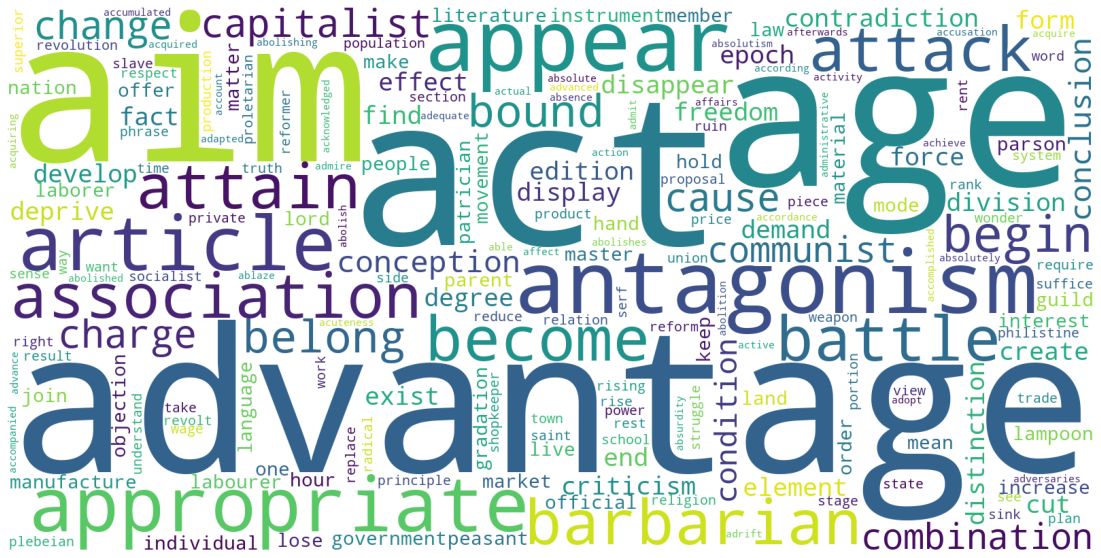

In [8]:
wordcloud = WordCloud(stopwords=stopwords, width=1600, height=800, background_color='white')\
            .generate(" ".join(wordlist))

plt.figure(figsize=(20,10))
plt.imshow(wordcloud)
plt.axis('off')
plt.show()

# You can also include a picture mask for the result

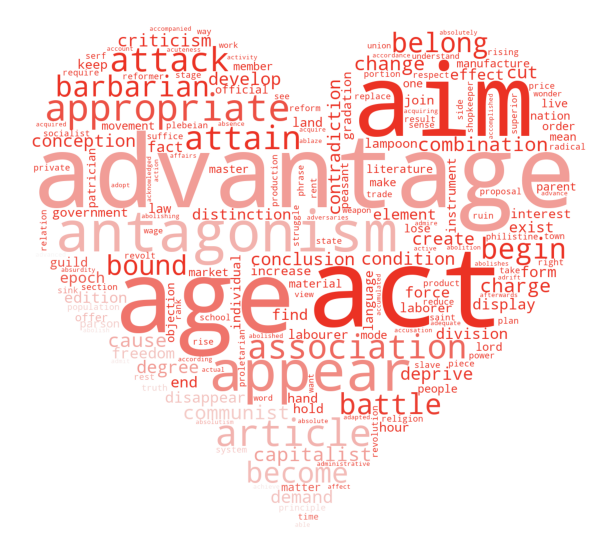

In [9]:
import numpy as np
from PIL import Image
from wordcloud import ImageColorGenerator

background_image = np.array(Image.open('data/heart.jpg'))
#background_image = np.array(Image.open('data/balloon.jpg'))

# mask = background_image
wordcloud = WordCloud(stopwords=stopwords, mask=background_image, width=1600, height=800, background_color='white')\
            .generate(" ".join(wordlist))

plt.figure(figsize=(20,10))

image_colors = ImageColorGenerator(background_image)
plt.imshow(wordcloud.recolor(color_func=image_colors))

plt.axis('off')
plt.show()